 1. IMPORT LIBRARIES

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectFromModel

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("Libraries imported successfully.")

Libraries imported successfully.


2. LOAD  DATASET AND VALIDATE REQUIRED COLUMNS

In [2]:
df = pd.read_csv("data/heart.csv")
print(df.shape)

(918, 12)


In [3]:
required_columns = [
    "Age",
    "Sex",
    "ChestPainType",
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "RestingECG",
    "MaxHR",
    "ExerciseAngina",
    "Oldpeak",
    "ST_Slope",
    "HeartDisease"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Dataset is missing required columns: {missing_columns}"
    )

print("Dataset column validation completed.")

Dataset column validation completed.


3. INITIAL DATA EXPLORATION

In [4]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [5]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


In [6]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [7]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [8]:
print("Data types:")
df.dtypes

Data types:


Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

4. DATA CLEANING AND VALIDATION

In [9]:
print("Missing values:")
print(df.isnull().sum())



Missing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


In [10]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [11]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (918, 12)


In [12]:
print("Age less than or equal to zero:")
print((df["Age"] <= 0).sum())

print("\nMaxHR less than or equal to zero:")
print((df["MaxHR"] <= 0).sum())

Age less than or equal to zero:
0

MaxHR less than or equal to zero:
0


In [13]:
print(df["HeartDisease"].value_counts())

HeartDisease
1    508
0    410
Name: count, dtype: int64


In [14]:
print("Unique target values:")
print(sorted(df["HeartDisease"].dropna().unique()))

if df["HeartDisease"].isnull().any():
    raise ValueError("The target column contains missing values.")

if not set(df["HeartDisease"].unique()).issubset({0, 1}):
    raise ValueError(
        "HeartDisease must contain only 0 and 1. "
        "Check the target encoding before continuing."
    )

print("Target validation completed.")

Unique target values:
[np.int64(0), np.int64(1)]
Target validation completed.


In [15]:
print(df["HeartDisease"].value_counts(normalize=True) * 100)

HeartDisease
1    55.337691
0    44.662309
Name: proportion, dtype: float64


5. EXPLORATORY DATA ANALYSIS

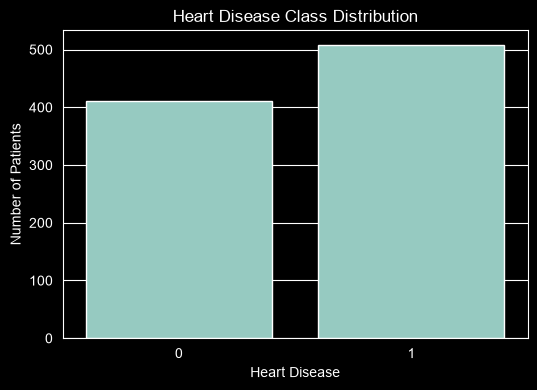

In [16]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="HeartDisease")

plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")

plt.show()

6. FEATURE ENGINEERING

In [17]:
df["MaxHR_Age_Ratio"] = (
    df["MaxHR"] / df["Age"].replace(0, np.nan)
)

print("Feature engineering completed.")

display(
    df[["Age", "MaxHR", "MaxHR_Age_Ratio"]].head()
)

Feature engineering completed.


,Age,MaxHR,MaxHR_Age_Ratio
0,40,172,4.300000
1,49,156,3.183673
2,37,98,2.648649
3,48,108,2.250000
4,54,122,2.259259


Summary of MaxHR_Age_Ratio:


count    918.000000
mean       2.684568
std        0.886525
min        1.030769
25%        2.062748
50%        2.510638
75%        3.155458
max        6.965517
Name: MaxHR_Age_Ratio, dtype: float64

Missing or infinite ratio values: 0


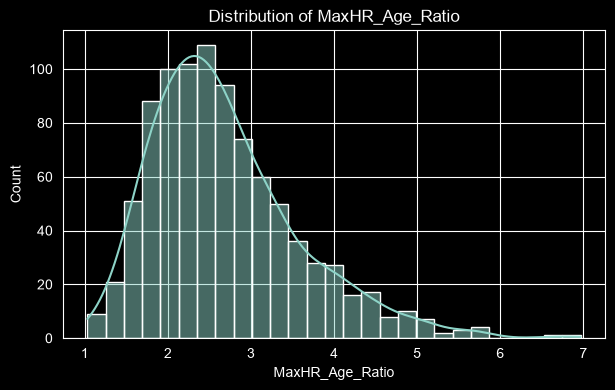

In [18]:
print("Summary of MaxHR_Age_Ratio:")
display(df["MaxHR_Age_Ratio"].describe())

print(
    "Missing or infinite ratio values:",
    (
        df["MaxHR_Age_Ratio"].isna()
        | ~np.isfinite(df["MaxHR_Age_Ratio"])
    ).sum()
)

plt.figure(figsize=(7, 4))
sns.histplot(
    df["MaxHR_Age_Ratio"].dropna(),
    kde=True
)
plt.title("Distribution of MaxHR_Age_Ratio")
plt.xlabel("MaxHR_Age_Ratio")
plt.show()

7. DEFINE FEATURES AND TARGET

In [19]:
X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (918, 12)
Target shape: (918,)


In [20]:
categorical_features = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope"
]

numerical_features = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "MaxHR",
    "Oldpeak",
    "MaxHR_Age_Ratio"
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

Numerical features:
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'MaxHR_Age_Ratio']


8. TRAIN TEST SPLIT

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training set: (734, 12)
Testing set: (184, 12)
Training target: (734,)
Testing target: (184,)


9. DATA PREPROCESSING

In [22]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [23]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (734, 21)
Testing data after preprocessing: (184, 21)


In [24]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))

print("\nProcessed feature names:")
for feature in feature_names:
    print(feature)

Number of processed features: 21

Processed feature names:
num__Age
num__RestingBP
num__Cholesterol
num__FastingBS
num__MaxHR
num__Oldpeak
num__MaxHR_Age_Ratio
cat__Sex_F
cat__Sex_M
cat__ChestPainType_ASY
cat__ChestPainType_ATA
cat__ChestPainType_NAP
cat__ChestPainType_TA
cat__RestingECG_LVH
cat__RestingECG_Normal
cat__RestingECG_ST
cat__ExerciseAngina_N
cat__ExerciseAngina_Y
cat__ST_Slope_Down
cat__ST_Slope_Flat
cat__ST_Slope_Up


In [25]:
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

X_train_processed_df.head()

,num__Age,num__RestingBP,num__Cholesterol,num__FastingBS,num__MaxHR,num__Oldpeak,num__MaxHR_Age_Ratio,cat__Sex_F,cat__Sex_M,cat__ChestPainType_ASY,cat__ChestPainType_ATA,cat__ChestPainType_NAP,cat__ChestPainType_TA,cat__RestingECG_LVH,cat__RestingECG_Normal,cat__RestingECG_ST,cat__ExerciseAngina_N,cat__ExerciseAngina_Y,cat__ST_Slope_Down,cat__ST_Slope_Flat,cat__ST_Slope_Up
485,0.970012,0.339016,0.127137,1.835497,-0.324520,0.317046,-0.708930,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
486,0.122028,-1.266031,0.099443,1.835497,1.689837,-0.440356,0.690330,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
117,0.546020,-0.159102,1.244113,1.835497,-0.247045,0.601071,-0.515395,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
361,-0.725956,1.501291,-1.876035,-0.544812,-0.479470,-0.819056,-0.025017,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
296,-0.407962,0.671094,-1.876035,1.835497,0.101594,-0.156330,0.134758,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0


# **MACHINE LEARNING IMPLEMENTATION**

10. FEATURE ENGINEERING EVALUATION

In [26]:
ratio_test_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

ratio_test_model.fit(
    X_train_processed,
    y_train
)

pred_with_ratio = ratio_test_model.predict(X_test_processed)
prob_with_ratio = ratio_test_model.predict_proba(X_test_processed)[:, 1]

X_train_without_ratio = X_train.drop(
    columns=["MaxHR_Age_Ratio"]
)

X_test_without_ratio = X_test.drop(
    columns=["MaxHR_Age_Ratio"]
)

numerical_without_ratio = [
    column for column in numerical_features
    if column != "MaxHR_Age_Ratio"
]

preprocessor_without_ratio = ColumnTransformer(
    transformers=[
        (
            "num",
            clone(numerical_transformer),
            numerical_without_ratio
        ),
        (
            "cat",
            clone(categorical_transformer),
            categorical_features
        )
    ],
    verbose_feature_names_out=False
)

train_without_ratio = preprocessor_without_ratio.fit_transform(
    X_train_without_ratio
)

test_without_ratio = preprocessor_without_ratio.transform(
    X_test_without_ratio
)

model_without_ratio = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

model_without_ratio.fit(train_without_ratio, y_train)

pred_without_ratio = model_without_ratio.predict(test_without_ratio)
prob_without_ratio = model_without_ratio.predict_proba(test_without_ratio)[:, 1]

ratio_comparison = pd.DataFrame([
    {
        "Experiment": "With MaxHR_Age_Ratio",
        "Accuracy": accuracy_score(y_test, pred_with_ratio),
        "F1 Score": f1_score(y_test, pred_with_ratio),
        "ROC-AUC": roc_auc_score(y_test, prob_with_ratio)
    },
    {
        "Experiment": "Without MaxHR_Age_Ratio",
        "Accuracy": accuracy_score(y_test, pred_without_ratio),
        "F1 Score": f1_score(y_test, pred_without_ratio),
        "ROC-AUC": roc_auc_score(y_test, prob_without_ratio)
    }
])

display(ratio_comparison.round(4))

,Experiment,Accuracy,F1 Score,ROC-AUC
0,With MaxHR_Age_Ratio,0.8696,0.8800,0.9344
1,Without MaxHR_Age_Ratio,0.8804,0.8911,0.9339


11. CLASS IMBALANCE ANALYSIS

In [27]:
print("Training class distribution before SMOTE:")
print(y_train.value_counts())

print("\nTraining class percentages:")
print(y_train.value_counts(normalize=True) * 100)

Training class distribution before SMOTE:
HeartDisease
1    406
0    328
Name: count, dtype: int64

Training class percentages:
HeartDisease
1    55.313351
0    44.686649
Name: proportion, dtype: float64


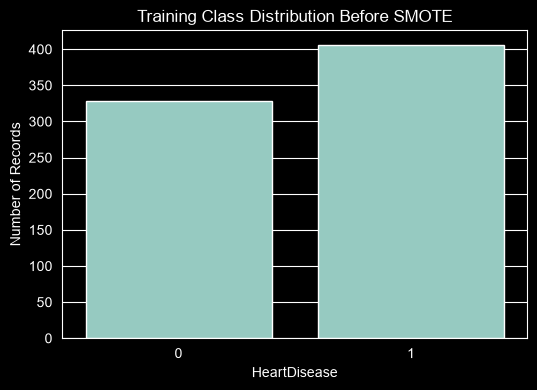

In [28]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title("Training Class Distribution Before SMOTE")
plt.xlabel("HeartDisease")
plt.ylabel("Number of Records")
plt.show()

12. APPLY SMOTE

In [29]:
smote = SMOTE(
    random_state=42
)
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed_df,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
HeartDisease
1    406
0    328
Name: count, dtype: int64

After SMOTE:
HeartDisease
1    406
0    406
Name: count, dtype: int64


In [30]:
print("Training features after SMOTE:", X_train_smote.shape)
print("Test features remain unchanged:", X_test_processed.shape)

Training features after SMOTE: (812, 21)
Test features remain unchanged: (184, 21)


13. XGBOOST FEATURE SELECTION

In [31]:
feature_selector_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

feature_selector_model.fit(
    X_train_smote,
    y_train_smote
)

selector = SelectFromModel(
    feature_selector_model,
    threshold="median",
    prefit=True
)

selected_features = X_train_smote.columns[selector.get_support()].tolist()

X_train_selected = X_train_smote[selected_features].copy()
X_test_selected = X_test_processed_df[selected_features].copy()

print("Original number of features:", X_train_smote.shape[1])
print("Selected number of features:", len(selected_features))
print("Training shape:", X_train_selected.shape)
print("Testing shape:", X_test_selected.shape)

print("\nSelected features:", selected_features)

Original number of features: 21
Selected number of features: 11
Training shape: (812, 11)
Testing shape: (184, 11)

Selected features: ['num__Cholesterol', 'num__FastingBS', 'num__Oldpeak', 'cat__Sex_F', 'cat__Sex_M', 'cat__ChestPainType_ASY', 'cat__RestingECG_LVH', 'cat__ExerciseAngina_N', 'cat__ExerciseAngina_Y', 'cat__ST_Slope_Flat', 'cat__ST_Slope_Up']


14. TRAINING FINAL XGBOOST MODEL

In [32]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(
    X_train_selected,
    y_train_smote
)

print("Final XGBoost model trained successfully.")

Final XGBoost model trained successfully.


15. GENERATE MODEL PREDICTIONS

In [33]:
y_pred = xgb_model.predict(X_test_selected)

y_probability = xgb_model.predict_proba(X_test_selected)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


16. MODEL EVALUATION

In [34]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

roc_auc = roc_auc_score(y_test, y_probability)

print("Model Evaluation Results")
print("------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Model Evaluation Results
------------------------
Accuracy : 0.8804
Precision: 0.8922
Recall   : 0.8922
F1 Score : 0.8922
ROC-AUC  : 0.9271


In [35]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Heart Disease", "Heart Disease"]
    )
)

                  precision    recall  f1-score   support

No Heart Disease       0.87      0.87      0.87        82
   Heart Disease       0.89      0.89      0.89       102

        accuracy                           0.88       184
       macro avg       0.88      0.88      0.88       184
    weighted avg       0.88      0.88      0.88       184



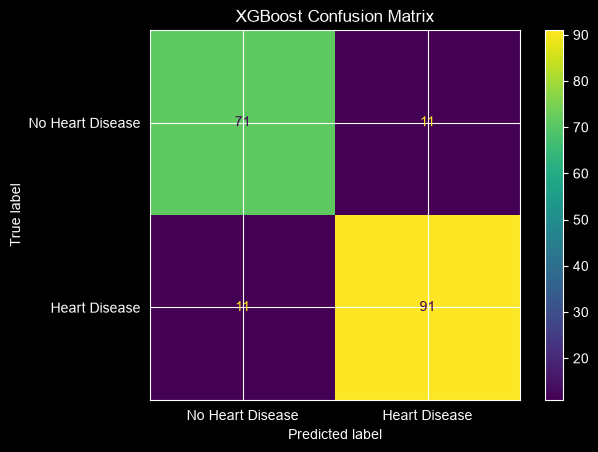

In [36]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Heart Disease", "Heart Disease"]
)

disp.plot()

plt.title("XGBoost Confusion Matrix")
plt.show()

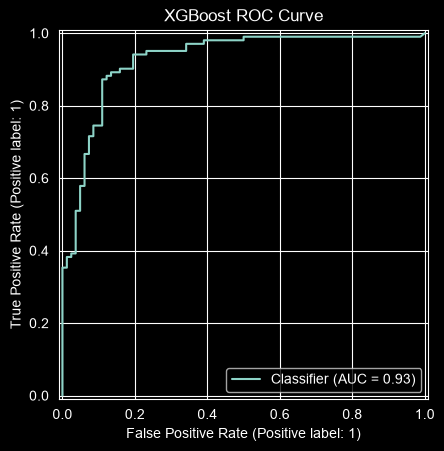

In [37]:
RocCurveDisplay.from_predictions(
    y_test,
    y_probability
)

plt.title("XGBoost ROC Curve")
plt.show()

17. FEATURE IMPORTANCE

In [38]:
importance = xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Importance": importance
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df

,Feature,Importance
10,cat__ST_Slope_Up,0.460486
9,cat__ST_Slope_Flat,0.128561
5,cat__ChestPainType_ASY,0.083078
7,cat__ExerciseAngina_N,0.067028
4,cat__Sex_M,0.052139
3,cat__Sex_F,0.043457
8,cat__ExerciseAngina_Y,0.035817
0,num__Cholesterol,0.034460
2,num__Oldpeak,0.033198
1,num__FastingBS,0.031484


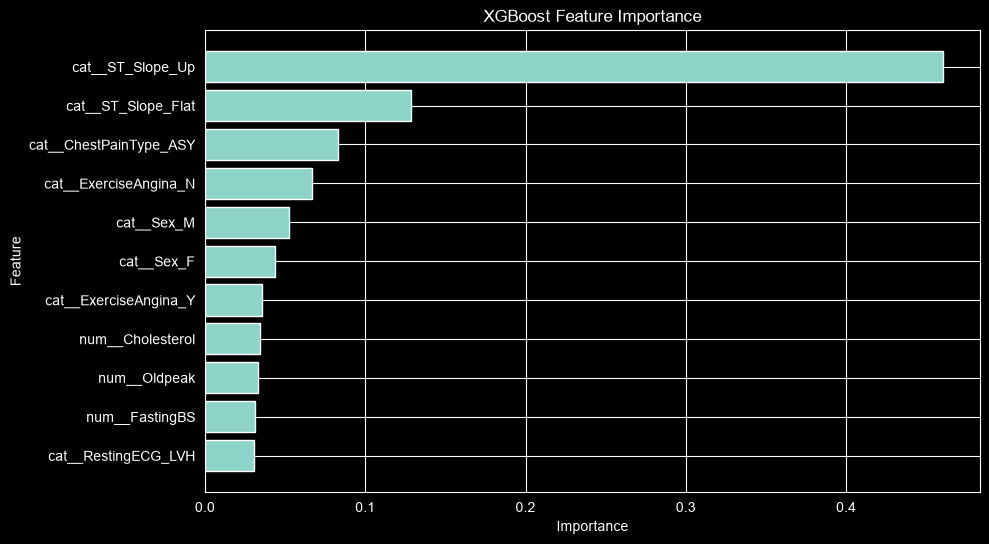

In [39]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")

plt.gca().invert_yaxis()

plt.show()

18. SAVE MODEL ARTIFACTS

In [40]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Models directory:", MODELS_DIR)

joblib.dump(preprocessor,MODELS_DIR / "preprocessor.pkl")
joblib.dump(selector,MODELS_DIR / "feature_selector.pkl")
joblib.dump(xgb_model,MODELS_DIR / "xgboost_model.pkl")
joblib.dump(selected_features,MODELS_DIR / "selected_features.pkl")

print("All ML components saved successfully.")

Models directory: C:\Users\Windows 10 Pro\PycharmProjects\CDSS_Project\models
All ML components saved successfully.


19. VERIFY MODEL ARTIFACTS

In [41]:
loaded_preprocessor = joblib.load(
    MODELS_DIR/"preprocessor.pkl"
)

loaded_selector = joblib.load(
    MODELS_DIR/"feature_selector.pkl"
)

loaded_model = joblib.load(
    MODELS_DIR/"xgboost_model.pkl"
)

loaded_features = joblib.load(
    MODELS_DIR/"selected_features.pkl"
)

print("Saved components loaded successfully.")

Saved components loaded successfully.


In [42]:
assert loaded_features == selected_features

assert (
    list(loaded_model.feature_names_in_)
    == loaded_features
)

print("Saved model artifacts verified successfully.")

Saved model artifacts verified successfully.


# **EXPLAINABLE AI IMPLEMENTATION**

20. SHAP GLOBAL EXPLAINABILITY

SHAP values generated successfully.


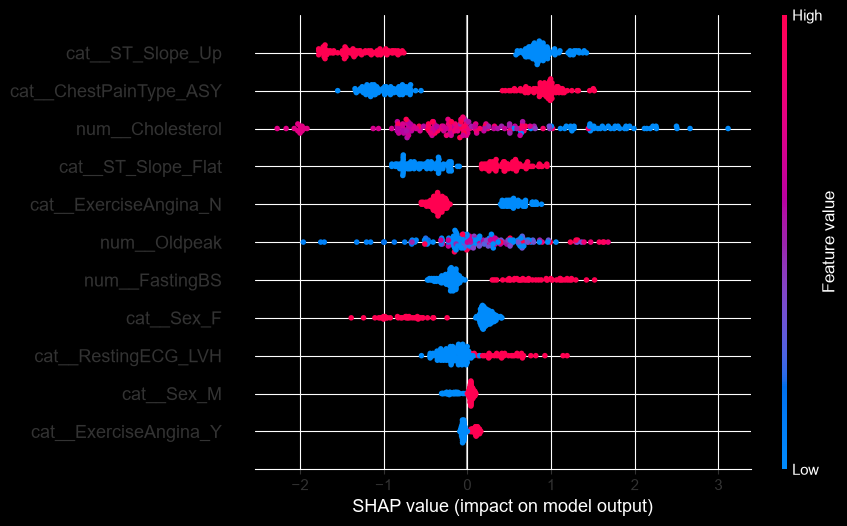

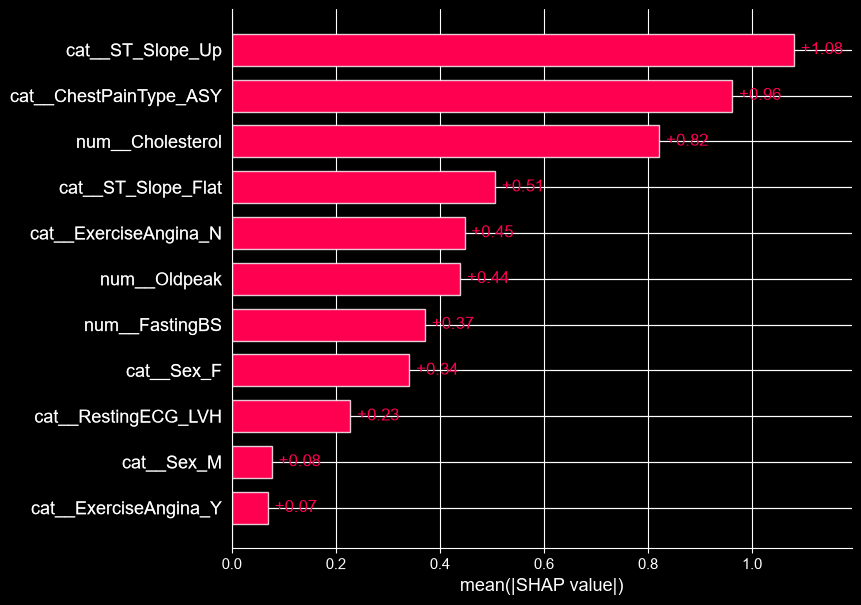

Both SHAP images saved successfully.


In [43]:

import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(loaded_model)

shap_values = explainer(X_test_selected)

print("SHAP values generated successfully.")

shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.savefig(
    MODELS_DIR / "shap_global_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.savefig(
    MODELS_DIR / "shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Both SHAP images saved successfully.")


21. SHAP INDIVIDUAL EXPLAINABILITY

Test record index: 0
Actual target: 1
Predicted class: 1
Predicted probability: 0.9526


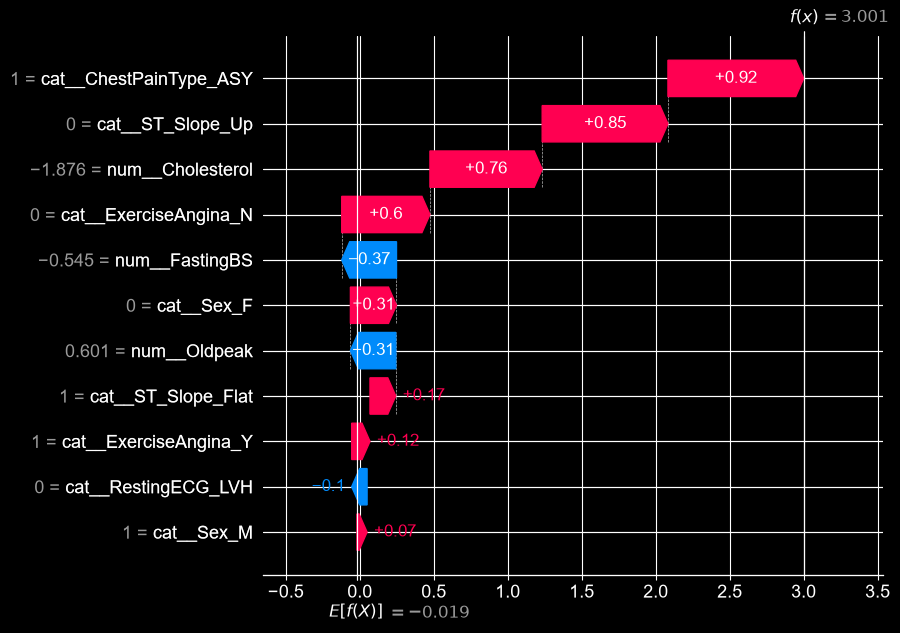

,Feature,Patient Feature Value,SHAP Value,Absolute SHAP Value
5,cat__ChestPainType_ASY,1.0000,0.9178,0.9178
10,cat__ST_Slope_Up,0.0000,0.8500,0.8500
0,num__Cholesterol,-1.8760,0.7587,0.7587
7,cat__ExerciseAngina_N,0.0000,0.5962,0.5962
1,num__FastingBS,-0.5448,-0.3702,0.3702
3,cat__Sex_F,0.0000,0.3115,0.3115
2,num__Oldpeak,0.6011,-0.3067,0.3067
9,cat__ST_Slope_Flat,1.0000,0.1744,0.1744
8,cat__ExerciseAngina_Y,1.0000,0.1238,0.1238
6,cat__RestingECG_LVH,0.0000,-0.1042,0.1042


Individual SHAP explanation saved successfully.


In [44]:
patient_index = 0

patient_features = X_test_selected.iloc[[patient_index]]

actual_value = int(y_test.iloc[patient_index])

predicted_class = int(
    loaded_model.predict(patient_features)[0]
)

predicted_probability = float(
    loaded_model.predict_proba(patient_features)[0, 1]
)

print("Test record index:", patient_index)
print("Actual target:", actual_value)
print("Predicted class:", predicted_class)
print("Predicted probability:", round(predicted_probability, 4))

shap.plots.waterfall(shap_values[patient_index],max_display=15,show=False)

plt.savefig(MODELS_DIR/"shap_individual_explanation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

individual_values = shap_values[patient_index].values
contribution_df = pd.DataFrame({
    "Feature": selected_features,
    "Patient Feature Value": patient_features.iloc[0].values,
    "SHAP Value": individual_values
})
contribution_df["Absolute SHAP Value"] = (contribution_df["SHAP Value"].abs())
contribution_df = contribution_df.sort_values(
    by="Absolute SHAP Value",
    ascending=False
)
display(contribution_df.round(4))
contribution_df.to_csv(MODELS_DIR/"shap_individual_contributions.csv",index=False)

print("Individual SHAP explanation saved successfully.")

22. SAVE SHAP ARTIFACTS

 Save the SHAP explainer

In [45]:
joblib.dump(
    explainer,
    MODELS_DIR/"shap_explainer.pkl"
)

print(
    "SHAP explainer saved to:",
    MODELS_DIR/"shap_explainer.pkl"
)


SHAP explainer saved to: C:\Users\Windows 10 Pro\PycharmProjects\CDSS_Project\models\shap_explainer.pkl


Save SHAP values

In [46]:
np.save(
    MODELS_DIR/"shap_values.npy",
    shap_values.values
)

print(
    "SHAP values saved to:",
    MODELS_DIR/"shap_values.npy"
)

SHAP values saved to: C:\Users\Windows 10 Pro\PycharmProjects\CDSS_Project\models\shap_values.npy
